In [ ]:
import os
os.environ['KAGGLE_USERNAME'] = "xxxxxx"
os.environ['KAGGLE_KEY'] = "xxxxxx"

from kaggle.api.kaggle_api_extended import KaggleApi
api = KaggleApi()
api.authenticate()
api.dataset_download_files("Cornell-University/arxiv", path="data", unzip=True)

Dataset URL: https://www.kaggle.com/datasets/Cornell-University/arxiv


In [5]:
import json
import pandas as pd

""" Choosing global: You can choose to reasonably subsample the dataset, or to focus on specific sub-views
(provided that the code scales up with data, as described in the last section). In these
cases, it is advisable that a global variable is used to trigger either subsampling or the
use of the whole data."""

# GLOBAL VARIABLE

ROWS_LIMIT = 100_000 # can be set to None to load entire json file (which has ~3M rows)

#loading data from json file of arxiv dataset
ids =[]
abstracts =[]
titles =[]
comments =[]
categories = []

with open("data/arxiv-metadata-oai-snapshot.json","r",encoding="utf-8") as f:
    for i, line in enumerate(f):
        if i == ROWS_LIMIT is not None and i>=ROWS_LIMIT:
            break
        paper = json.loads(line)
        ids.append(paper['id'])
        abstracts.append(paper['abstract'])
        titles.append(paper['title'])
        comments.append(paper['comments'])
        categories.append(paper['categories'])

#making a pandas dataframe
df = pd.DataFrame({'id': ids,'abstract': abstracts,'title': titles, 'comments': comments,'categories': categories})

#print(df.shape)
df.head()

,id,abstract,title,comments,categories
0,0704.0001,A fully differential calculation in perturba...,Calculation of prompt diphoton production cros...,"37 pages, 15 figures; published version",hep-ph
1,0704.0002,"We describe a new algorithm, the $(k,\ell)$-...",Sparsity-certifying Graph Decompositions,To appear in Graphs and Combinatorics,math.CO cs.CG
2,0704.0003,The evolution of Earth-Moon system is descri...,The evolution of the Earth-Moon system based o...,"23 pages, 3 figures",physics.gen-ph
3,0704.0004,We show that a determinant of Stirling cycle...,A determinant of Stirling cycle numbers counts...,11 pages,math.CO
4,0704.0005,In this paper we show how to compute the $\L...,From dyadic $\Lambda_{\alpha}$ to $\Lambda_{\a...,NaN,math.CA math.FA


In [14]:
##To preprocess data, i decided to leave latex expressions as separate tokens, because there are datasets that have identical text 
## with only latex formulas being different. 

In [6]:
import re #regular expression library
import unicodedata  ## to normalize text


# my tokens where i save latex and math as tokens too
my_token = re.compile(
    r"(?P<math>\$(?=\S)(?:\\.|[^$\\]){1,200}?(?<=\S)\$(?!\d))" #for latex like $a+b$
    r"|(?P<cmd>\\[A-Za-z]+)"      #for simple latex like \Delta
    r"|(?P<word>\w+(?:[.'-]\w+)*)", #word/number
    re.DOTALL #to prevent from getting lost math expressions with newlines
)

def abstract_tokenized(text):
    text = unicodedata.normalize("NFKC", text)
    tokens =[]
    for token in my_token.finditer(text):
        if token.lastgroup== "word":
            tokens.append(token.group().lower())
        else:
            tokens.append(re.sub(r"\s+", "", token.group()))
    return tokens

In [7]:
df['tokens']=df['abstract'].apply(abstract_tokenized)

In [8]:
lengths = df['tokens'].apply(len)
lengths.describe()

count    100000.000000
mean        121.932910
std          62.969981
min           2.000000
25%          76.000000
50%         110.000000
75%         158.000000
max         461.000000
Name: tokens, dtype: float64

In [9]:
## Dropping abstracts that have less than 20 tokens. Thus empty or NaN absracts are also dropped

In [10]:
df = df[df['tokens'].apply(len)>= 20].copy() ##empty dropped too

In [11]:
len(df['tokens'])

98821

In [21]:
mask = df['comments'].str.contains(
    r'withdraw| withdrawn |withdrew |withdrawing | withdrawal',
    case=False,
    na=False
)

#print(mask.sum())
df = df[~mask].copy() #drop withdrawn articles based on comments, because an abstract can possible have the word withdraw in it properly

In [22]:
len(df)

98500

In [23]:
## Chosen encoding: k=3 word shingling
k=3
def shingling(tokens):
    return {
        tuple(tokens[i:i+k])
        for i in range(len(tokens)-k+1)
    }

df['shingles'] = df['tokens'].apply(shingling)

In [24]:
len(df['tokens'].iloc[0])

142

In [25]:
len(df['shingles'].iloc[0])
#before and after shingling lengths

140

### Minhash algorithm

In [26]:
import numpy as np
import hashlib # to encode text 


#Choosing 128 as number of hash functions/signature length
n = 128
modulus = 2**31-1
rng = np.random.default_rng(42)

a = rng.integers(1, modulus, size=n,dtype=np.int64)
b = rng.integers(0, modulus,size=n,dtype=np.int64)

def int_shingles(shingle):
    text = ' '.join(shingle)
    hash_bytes = hashlib.sha256(text.encode('utf-8')).digest()
    return int.from_bytes(hash_bytes[:8], byteorder='big') %modulus
  
  
### Minhash Function
def minhash(shingles):
    signature = np.full(n, modulus, dtype=np.int64) # The book says default values are inf, here i use 2**31-1 as default value

    for shingle in shingles:
        x = int_shingles(shingle)
        hashes =(a*x + b) % modulus
        signature = np.minimum(signature, hashes)
    return signature

In [27]:
df['minhash'] = [
    minhash(shingles)
    for shingles in df['shingles']
]

In [28]:
df['minhash'].head()

0    [12384938, 4379812, 1031775, 16422157, 1423649...
1    [24948227, 15853109, 5689868, 45933968, 360238...
2    [8055121, 24027787, 9877329, 921880, 19646788,...
3    [183797475, 44447119, 19250126, 98330159, 5132...
4    [10071368, 94012260, 137134596, 97204497, 9083...
Name: minhash, dtype: object

### LSH algorithm

In [29]:
#Choosing bands and rows for 128  as 32, 4:

b=32
r=4

buckets = {} #in dictionary will be saved bands index and values and which abstracts have them

for index, signature in enumerate(df['minhash']):

    for band in range(b):

        start = band*r
        band_values = tuple(signature[start:start + r])
        key =(band,band_values)

        if key not in buckets:
            buckets[key] =[]

        buckets[key].append(index)

#identify ing candidate pairs
candidate_pairs = set()

for bucket in buckets.values():

    if len(bucket) > 1:
        for i in range(len(bucket)):
            for j in range(i + 1, len(bucket)):
                pair = (bucket[i], bucket[j])
                candidate_pairs.add(pair)

#print(f"Number of buckets: {len(buckets)}")
print(f"Number of candidate pairs: {len(candidate_pairs)}")

Number of candidate pairs: 1268


In [30]:
## JACCARD

In [31]:
def jaccard(set1, set2):
    return len(set1&set2) / len(set1|set2) if len(set1|set2) else 0

chosen_threshold =0.5
similar_pairs =[]

for i, j in candidate_pairs:
    score = jaccard(df['shingles'].iloc[i], df['shingles'].iloc[j])
    if score >= chosen_threshold:
        similar_pairs.append((i, j, score))

print(f"Number of abstracts: {len(df)}")
#print(f"Number of LSH buckets: {len(buckets)}")
#print(f"Number of candidate pairs: {len(candidate_pairs)}")
print(f"Number of similar pairs where Jaccard similarity >= {chosen_threshold} is: {len(similar_pairs)} pairs")

Number of abstracts: 98500
Number of similar pairs where Jaccard similarity >= 0.5 is: 625 pairs


In [32]:
#looking at results to imprive code/for report

for i, j, score in sorted(similar_pairs, key=lambda x: x[2], reverse=True):
    print(f"\nJaccard similarity score: {score:.3f}")
    print(f"First paper: {df.iloc[i]['id']}, TITLE: {df.iloc[i]['title']},\n ABSTRACT: {df.iloc[i]['abstract']}")
    print(f"Second paper: {df.iloc[j]['id']}, TITLE: {df.iloc[j]['title']},\n ABSTRACT: {df.iloc[j]['abstract']}")
    print("*"*100)


Jaccard similarity score: 1.000
First paper: 0803.2932, TITLE: Singlet fermionic dark matter,
 ABSTRACT:   We propose a renormalizable model of a fermionic dark matter by introducing a
gauge singlet Dirac fermion and a real singlet scalar. The bridges between the
singlet sector and the standard model sector are only the singlet scalar
interaction terms with the standard model Higgs field. The singlet fermion
couples to the standard model particles through the mixing between the standard
model Higgs and singlet scalar and is naturally a weakly interacting massive
particle (WIMP). The measured relic abundance can be explained by the singlet
fermionic dark matter as the WIMP within this model. Collider implication of
the singlet fermionic dark matter is also discussed. Predicted is the elastic
scattering cross section of the singlet fermion into target nuclei for a direct
detection of the dark matter. Search of the direct detection of the dark matter
provides severe constraints on the pa

In [33]:
#comparing algorithm performance

comparisons=[]

for i, j, jac_score in similar_pairs:
    sig1=df['minhash'].iloc[i]
    sig2= df['minhash'].iloc[j]
    minhash_score = np.mean(sig1==sig2)

    comparisons.append({
        'id_1': df['id'].iloc[i],
        'id_2': df['id'].iloc[j],
        'jaccard': jac_score,
        'minhash': minhash_score,
        'absolute_error': abs(jac_score - minhash_score)
    })

comp_df = pd.DataFrame(comparisons)

comp_df.sort_values('jaccard', ascending=False)

,id_1,id_2,jaccard,minhash,absolute_error
8,0803.2932,0809.2745,1.0,1.000000,0.000000
624,0710.5072,0710.5077,1.0,1.000000,0.000000
9,0710.5074,0710.5077,1.0,1.000000,0.000000
606,0710.5072,0710.5074,1.0,1.000000,0.000000
605,0710.5084,0710.5085,1.0,1.000000,0.000000
...,...,...,...,...,...
7,0806.4250,0809.2669,0.5,0.523438,0.023438
148,0710.3035,0802.4028,0.5,0.515625,0.015625
234,0710.0526,0710.3346,0.5,0.453125,0.046875
313,0708.1825,0711.2651,0.5,0.468750,0.031250


In [34]:
print("Mean absolute error:", comp_df['absolute_error'].mean())
print("Median absolute error:", comp_df['absolute_error'].median())
print("Maximum absolute error:", comp_df['absolute_error'].max())

Mean absolute error: 0.024445076353884154
Median absolute error: 0.01822916666666663
Maximum absolute error: 0.10727370689655169


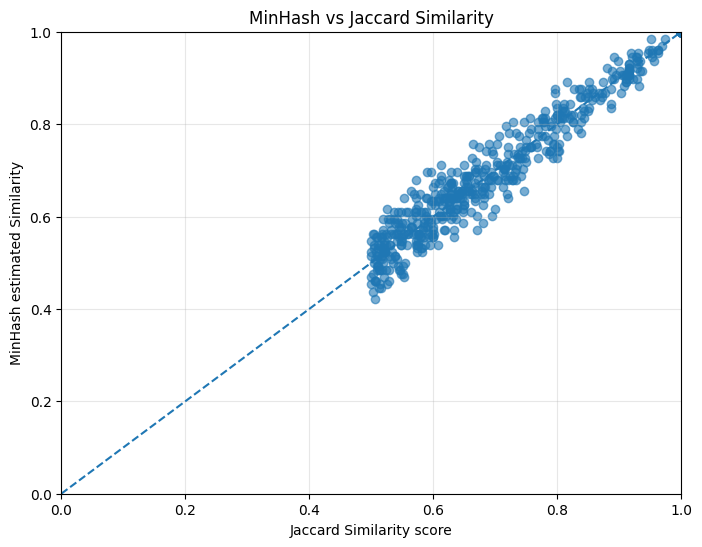

In [56]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
plt.scatter(comp_df['jaccard'],comp_df['minhash'],alpha=0.6)
# line
plt.plot([0,1], [0,1], linestyle='--')

plt.xlabel('Jaccard Similarity score')
plt.ylabel('MinHash estimated Similarity')
plt.title('MinHash vs Jaccard Similarity')

plt.xlim(0,1)
plt.ylim(0,1)
plt.grid(alpha=0.3)

plt.show()